# Проект - нейросеть для предсказания калорийности блюд

## Блок инициализации

In [1]:
# импорты
import pathlib as path
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# local scripts
import scripts.utils as utils

model_config = utils.MealModelConfig()

SEED = model_config.SEED

# задание случайностей - seed
utils.set_random(SEED)

# перенести в .env?
DATA_PATH = path.Path('data')

## Этап 2 - реализация пайплайна обучения

### Пайплайн обучения

In [ ]:
import importlib 
import scripts.dataset as dataset
import scripts.utils as utils

importlib.reload(dataset)
importlib.reload(utils)

#### Эксперимент 1 - замороженные модели + fusion-слой

In [20]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.dataset as dataset
import scripts.utils as utils

config = utils.MealModelConfig()

utils.set_random(config.SEED)
log = partial(utils.log_fn, config=config)

tokenizer = AutoTokenizer.from_pretrained(config.TEXT_MODEL_NAME)

train_dataset = dataset.MealDataset(model_config=config, split='train')
train_dataloader = DataLoader(dataset=train_dataset, batch_size=config.N_BATCH, shuffle=True, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

val_dataset = dataset.MealDataset(model_config=config, split='test')
val_dataloader = DataLoader(dataset=val_dataset, batch_size=config.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model = utils.MealModelNN(config=config) 

# разморозка параметров
utils.unfreeze_model_params(model, config)

# подключаем обучаемые (активные) параметры к оптимизатору
optimizer = torch.optim.AdamW([
    # [TODO] проверить/почистить пустые группы, если нет обучаемых параметров
    {'params': [p for p in model.text_model.parameters() if p.requires_grad], 'lr': config.LR_TEXT_MODEL},
    {'params':[p for p in model.img_model.parameters() if p.requires_grad], 'lr': config.LR_IMG_MODEL},
    
    {'params': model.text_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.img_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.norm_layer.parameters(), 'lr': config.LR_PROJ},
    {'params': model.fusion.parameters(), 'lr': config.LR_FUSION},
    {'params': model.regression_head.parameters(), 'lr': config.LR_REGRESSION_HEAD}
])

# проверка, что все активные параметры добавлены в оптимизатор
utils.optimizer_params_sanity_check(model, optimizer)

# - прогрев learning rate warmup
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda step: min(1.0, step / 200)  # 200 шагов ≈ 1+ эпоха
)

print(f'batch size = {config.N_BATCH}')
print(f'n_iter = {config.N_ITER}')
print(f'train iterations/batch = {len(train_dataloader)}')
print(f'val iterations/batch = {len(val_dataloader)}')

train_loss_history = []
train_mae_history = []
train_time_history = []
val_loss_history = []
val_mae_history = []
val_time_history = []
best_metric = 1000
best_epoch = -1
for epoch in range(config.N_EPOCHS):
    train_huber_loss, train_metric_mae, train_time = utils.train(model=model, config=config, optimizer=optimizer, dataloader=train_dataloader, scheduler=scheduler)
    train_loss_history.append(train_huber_loss)
    train_mae_history.append(train_metric_mae)
    train_time_history.append(train_time)

    val_loss_huber, val_metric_mae, val_time = utils.validate(model=model, config=config, dataloader=val_dataloader)
    val_loss_history.append(val_loss_huber)
    val_mae_history.append(val_metric_mae)
    val_time_history.append(val_time)

    print(f'epoch - {epoch}: train mae = {train_metric_mae:.2f}, train_loss = {train_huber_loss:.2f}/{train_time:.2f} sec, val_mae = {val_metric_mae:.2f}, val_loss = {val_loss_huber:.2f}/{val_time:.2f} sec')
       
    if val_metric_mae < best_metric:
        best_metric = val_metric_mae
        best_epoch = epoch
        utils.save_model(model, config)

    # если метрика не уменьшается в течение config.PATIENCE эпох подряд, то останавливаем обучение
    if (epoch - best_epoch) >= config.PATIENCE:
        print(f'early stopping - metric is not increasing for [{config.PATIENCE}] epochs')
        break


    if val_metric_mae < config.TARGET_METRIC:
        print(f'!! target metric reached = {config.TARGET_METRIC}, stop training')
        break

# save train logs
log_path  = path.Path(config.MODEL_LOG_SAVE_PATH)
log_path.mkdir(exist_ok=True)

pd.DataFrame(train_loss_history, columns=['loss_huber']).to_csv(log_path / 'train_loss_history.csv', index=False)
pd.DataFrame(train_mae_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_history.csv', index=False)
pd.DataFrame(train_time_history, columns=['time']).to_csv(log_path / 'train_time_history.csv', index=False)

pd.DataFrame(val_loss_history, columns=['loss_huber']).to_csv(log_path / 'val_loss_history.csv', index=False)
pd.DataFrame(val_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_history.csv', index=False)
pd.DataFrame(val_time_history, columns=['time']).to_csv(log_path / 'val_time_history.csv', index=False)

expected TARGET_MEAN = 255, real data =  255.31
expected TARGET_STD  = 221, real data = 220.71
batch size = 8
n_iter = -1
train iterations/batch = 342
val iterations/batch = 63
   --- train()


training:  15%|█▍        | 50/342 [02:02<12:07,  2.49s/it]

running_huber = 0.3460, running_mae = 159.2517


training:  29%|██▉       | 100/342 [04:06<09:36,  2.38s/it]

running_huber = 0.3295, running_mae = 150.8322


training:  44%|████▍     | 150/342 [06:13<07:51,  2.46s/it]

... (151 outputs left out)

training: 100%|██████████| 342/342 [11:47<00:00,  2.07s/it]


   -- validate()


validation: 100%|██████████| 63/63 [02:01<00:00,  1.93s/it]

epoch - 9: train mae = 81.07, train_loss = 0.13/707.25 sec, val_mae = 86.12, val_loss = 0.16/121.69 sec


##### Печать журнала обучения

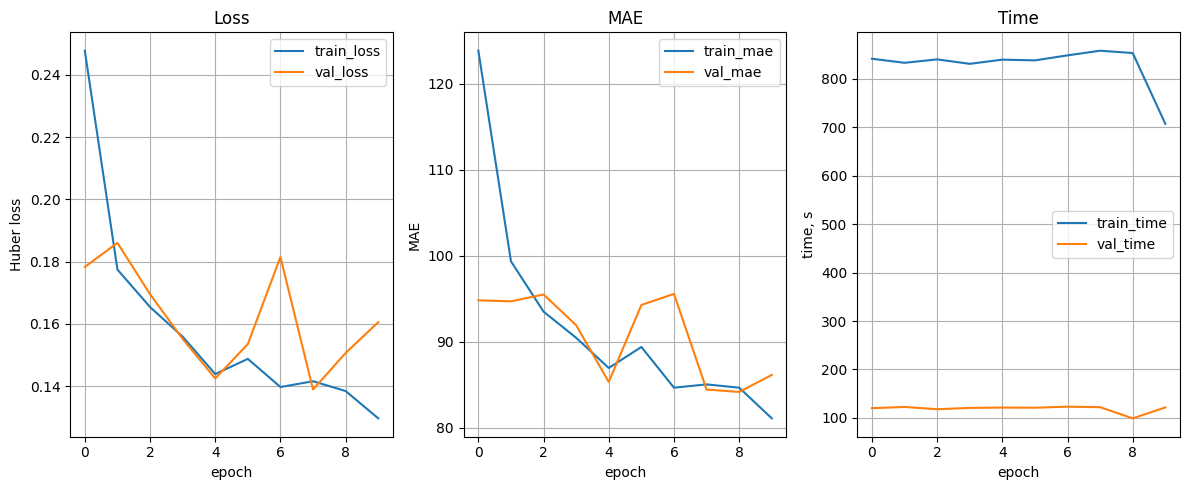

In [26]:
import matplotlib.pyplot as plt

fix, axs = plt.subplots(1,3, figsize=(12,5))
ax=axs[0]
ax.plot(train_loss_history)
ax.plot(val_loss_history)
ax.grid();ax.set_xlabel('epoch');ax.set_ylabel('Huber loss');ax.legend(['train_loss', 'val_loss'])
ax.set_title('Loss')

ax=axs[1]
ax.plot(train_mae_history)
ax.plot(val_mae_history)
ax.grid();ax.set_xlabel('epoch');ax.set_ylabel('MAE');ax.legend(['train_mae', 'val_mae'])
ax.set_title('MAE')

ax=axs[2]
ax.plot(train_time_history)
ax.plot(val_time_history)
ax.grid();ax.set_xlabel('epoch');ax.set_ylabel('time, s');l=ax.legend(['train_time', 'val_time'])
ax.set_title('Time')

plt.tight_layout()

Копия результатов данного эксперимента (модель и журнал обучения) сохранены в `data/model/experiment1`

##### Чистая проверка на тесте обученной модели

In [22]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.dataset as dataset
import scripts.utils as utils

config = utils.MealModelConfig()

utils.set_random(config.SEED)

tokenizer = AutoTokenizer.from_pretrained(config.TEXT_MODEL_NAME)
val_dataset = dataset.MealDataset(model_config=config, split='test')
val_dataloader = DataLoader(dataset=val_dataset, batch_size=config.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model_exp1 = utils.MealModelNN(config=config) 
# load trained model
model_exp1.load_state_dict(torch.load(path.Path(config.MODEL_SAVE_PATH) / 'experiment-1' / config.MODEL_SAVE_NAME))
 
loss_huber, metric_mae, time = utils.validate(model=model_exp1, config=config, dataloader=val_dataloader)
print(f'Test metric - MAE = {metric_mae}')


   -- validate()


validation: 100%|██████████| 63/63 [02:01<00:00,  1.93s/it]

Test metric - MAE = 83.65887272547162


### Эксперимент 2 - разморозка весов

In [ ]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.dataset as dataset
import scripts.utils as utils

config = utils.MealModelConfig()

utils.set_random(config.SEED)
log = partial(utils.log_fn, config=config)

tokenizer = AutoTokenizer.from_pretrained(config.TEXT_MODEL_NAME)

train_dataset = dataset.MealDataset(model_config=config, split='train')
train_dataloader = DataLoader(dataset=train_dataset, batch_size=config.N_BATCH, shuffle=True, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

val_dataset = dataset.MealDataset(model_config=config, split='test')
val_dataloader = DataLoader(dataset=val_dataset, batch_size=config.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model = utils.MealModelNN(config=config) 

# разморозка параметров
utils.unfreeze_model_params(model, config)

# подключаем обучаемые (активные) параметры к оптимизатору
optimizer = torch.optim.AdamW([
    {'params': [p for p in model.text_model.parameters() if p.requires_grad], 'lr': config.LR_TEXT_MODEL},
    {'params':[p for p in model.img_model.parameters() if p.requires_grad], 'lr': config.LR_IMG_MODEL},
    
    {'params': model.text_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.img_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.norm_layer.parameters(), 'lr': config.LR_PROJ},
    {'params': model.fusion.parameters(), 'lr': config.LR_FUSION},
    {'params': model.regression_head.parameters(), 'lr': config.LR_REGRESSION_HEAD}
])

# проверка, что все активные параметры добавлены в оптимизатор
utils.optimizer_params_sanity_check(model, optimizer)

# - прогрев learning rate warmup
iters_per_epoch = len(train_dataloader)
warmup_steps = int(1.7 * iters_per_epoch)   # ≈1.7 эпохи
print(f'warmup_steps = {warmup_steps}')
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda step: min(1.0, step / warmup_steps)  # 150 шагов ≈ 1.7 эпохи при BATCH=32
)

print(f'batch size = {config.N_BATCH}')
print(f'n_iter = {config.N_ITER}')
print(f'train iterations/batch = {len(train_dataloader)}')
print(f'val iterations/batch = {len(val_dataloader)}')

train_loss_history = []
train_mae_history = []
train_time_history = []
val_loss_history = []
val_mae_history = []
val_time_history = []
best_metric = 1000
best_epoch = -1
for epoch in range(config.N_EPOCHS):
    train_huber_loss, train_metric_mae, train_time = utils.train(model=model, config=config, optimizer=optimizer, dataloader=train_dataloader, scheduler=scheduler)
    train_loss_history.append(train_huber_loss)
    train_mae_history.append(train_metric_mae)
    train_time_history.append(train_time)

    val_loss_huber, val_metric_mae, val_time = utils.validate(model=model, config=config, dataloader=val_dataloader)
    val_loss_history.append(val_loss_huber)
    val_mae_history.append(val_metric_mae)
    val_time_history.append(val_time)

    print(f'epoch - {epoch}: train mae = {train_metric_mae:.2f}, train_loss = {train_huber_loss:.2f}/{train_time:.2f} sec, val_mae = {val_metric_mae:.2f}, val_loss = {val_loss_huber:.2f}/{val_time:.2f} sec')
       
    if val_metric_mae < best_metric:
        best_metric = val_metric_mae
        best_epoch = epoch
        utils.save_model(model, config)

    # если метрика не уменьшается в течение config.PATIENCE эпох подряд, то останавливаем обучение
    if (epoch - best_epoch) >= config.PATIENCE:
        print(f'early stopping - metric is not increasing for [{config.PATIENCE}] epochs')
        break


    if val_metric_mae < config.TARGET_METRIC:
        print(f'!! target metric reached = {config.TARGET_METRIC}, stop training')
        break

# save train logs
log_path  = path.Path(config.MODEL_LOG_SAVE_PATH)
log_path.mkdir(exist_ok=True)

pd.DataFrame(train_loss_history, columns=['loss_huber']).to_csv(log_path / 'train_loss_history.csv', index=False)
pd.DataFrame(train_mae_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_history.csv', index=False)
pd.DataFrame(train_time_history, columns=['time']).to_csv(log_path / 'train_time_history.csv', index=False)

pd.DataFrame(val_loss_history, columns=['loss_huber']).to_csv(log_path / 'val_loss_history.csv', index=False)
pd.DataFrame(val_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_history.csv', index=False)
pd.DataFrame(val_time_history, columns=['time']).to_csv(log_path / 'val_time_history.csv', index=False)

expected TARGET_MEAN = 255, real data =  255.31
expected TARGET_STD  = 221, real data = 220.71
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.q_lin.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.q_lin.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.k_lin.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.k_lin.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.v_lin.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.v_lin.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.out_lin.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.out_lin.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.sa_layer_norm.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.sa_l

training:  58%|█████▊    | 50/86 [00:38<00:27,  1.33it/s]

running_huber = 0.3688, running_mae = 162.2595


training: 100%|██████████| 86/86 [01:05<00:00,  1.31it/s]


   -- validate()


validation: 100%|██████████| 16/16 [00:11<00:00,  1.43it/s]


... (87 outputs left out)

training: 100%|██████████| 86/86 [01:06<00:00,  1.30it/s]


   -- validate()


validation: 100%|██████████| 16/16 [00:11<00:00,  1.43it/s]

epoch - 15: train mae = 58.53, train_loss = 0.07/66.15 sec, val_mae = 71.79, val_loss = 0.11/11.17 sec
early stopping - metric is not increasing for [4] epochs


### Эксперимент 3 - отказ от GAP (global average pooling)


- логи перенесены сюда (обучение было прервано, ВМ самоликвидировалась)

```
expected TARGET_MEAN = 255, real data =  255.31
expected TARGET_STD  = 221, real data = 220.71
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.q_lin.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.q_lin.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.k_lin.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.k_lin.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.v_lin.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.v_lin.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.out_lin.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.out_lin.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.sa_layer_norm.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.sa_layer_norm.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.ffn.lin1.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.ffn.lin1.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.ffn.lin2.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.ffn.lin2.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.output_layer_norm.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.output_layer_norm.bias
mobilenetv4_conv_aa_large - parameter id unfreezed: blocks.4.0.conv.weight
mobilenetv4_conv_aa_large - parameter id unfreezed: blocks.4.0.bn1.weight
mobilenetv4_conv_aa_large - parameter id unfreezed: blocks.4.0.bn1.bias
mobilenetv4_conv_aa_large - parameter id unfreezed: conv_head.weight
mobilenetv4_conv_aa_large - parameter id unfreezed: norm_head.weight
mobilenetv4_conv_aa_large - parameter id unfreezed: norm_head.bias
warmup_steps = 146
...
n_iter = -1
train iterations/batch = 86
val iterations/batch = 16
   --- train()
Output is truncated. View as a scrollable element or open in a text editor. Adjust cell output settings...
training:  58%|█████▊    | 50/86 [00:41<00:28,  1.25it/s]
running_huber = 0.3605, running_mae = 157.3070
training: 100%|██████████| 86/86 [01:10<00:00,  1.22it/s]
   -- validate()
validation: 100%|██████████| 16/16 [00:14<00:00,  1.10it/s]
epoch - 0: train mae = 146.01, train_loss = 0.32/70.59 sec, val_mae = 121.56, val_loss = 0.26/14.59 sec
model saved to - [data/model/best_model.pth]
   --- train()
training:  58%|█████▊    | 50/86 [00:40<00:28,  1.26it/s]
running_huber = 0.2491, running_mae = 122.0855
training: 100%|██████████| 86/86 [01:08<00:00,  1.25it/s]
   -- validate()
validation: 100%|██████████| 16/16 [00:11<00:00,  1.40it/s]
epoch - 1: train mae = 119.60, train_loss = 0.24/68.72 sec, val_mae = 128.76, val_loss = 0.27/11.42 sec
   --- train()
training:  58%|█████▊    | 50/86 [00:40<00:28,  1.26it/s]
running_huber = 0.2108, running_mae = 109.5317
training: 100%|██████████| 86/86 [01:08<00:00,  1.25it/s]
   -- validate()
validation: 100%|██████████| 16/16 [00:11<00:00,  1.40it/s]
epoch - 2: train mae = 109.99, train_loss = 0.21/68.79 sec, val_mae = 126.83, val_loss = 0.26/11.43 sec
   --- train()
training:  58%|█████▊    | 50/86 [00:40<00:32,  1.12it/s]
running_huber = 0.1972, running_mae = 105.1262
training: 100%|██████████| 86/86 [01:10<00:00,  1.22it/s]
   -- validate()
validation: 100%|██████████| 16/16 [00:11<00:00,  1.40it/s]
epoch - 3: train mae = 105.19, train_loss = 0.20/70.69 sec, val_mae = 111.91, val_loss = 0.22/11.40 sec
model saved to - [data/model/best_model.pth]
   --- train()
training:  58%|█████▊    | 50/86 [00:39<00:28,  1.25it/s]
running_huber = 0.1855, running_mae = 99.1663
training: 100%|██████████| 86/86 [01:08<00:00,  1.26it/s]
   -- validate()
validation: 100%|██████████| 16/16 [00:12<00:00,  1.33it/s]
epoch - 4: train mae = 98.14, train_loss = 0.18/68.13 sec, val_mae = 110.46, val_loss = 0.21/12.08 sec
model saved to - [data/model/best_model.pth]
   --- train()
training:  58%|█████▊    | 50/86 [00:39<00:28,  1.25it/s]
running_huber = 0.1704, running_mae = 94.4913
training: 100%|██████████| 86/86 [01:08<00:00,  1.26it/s]
   -- validate()
validation: 100%|██████████| 16/16 [00:11<00:00,  1.40it/s]
epoch - 5: train mae = 95.39, train_loss = 0.17/68.08 sec, val_mae = 91.88, val_loss = 0.17/11.40 sec
model saved to - [data/model/best_model.pth]
   --- train()
training:  58%|█████▊    | 50/86 [00:39<00:28,  1.26it/s]
running_huber = 0.1576, running_mae = 90.7893
training: 100%|██████████| 86/86 [01:08<00:00,  1.26it/s]
   -- validate()
validation: 100%|██████████| 16/16 [00:11<00:00,  1.40it/s]
epoch - 6: train mae = 91.03, train_loss = 0.16/68.03 sec, val_mae = 88.72, val_loss = 0.15/11.39 sec
model saved to - [data/model/best_model.pth]
   --- train()
training:  58%|█████▊    | 50/86 [00:39<00:29,  1.24it/s]
running_huber = 0.1517, running_mae = 89.8365
training: 100%|██████████| 86/86 [01:08<00:00,  1.26it/s]
   -- validate()
validation: 100%|██████████| 16/16 [00:11<00:00,  1.40it/s]
epoch - 7: train mae = 89.35, train_loss = 0.15/68.13 sec, val_mae = 99.94, val_loss = 0.18/11.45 sec

выполнение прервано

```

### Эксперимент 4 - 2-х задачное предсказание массы и калорий + масштабирование
описание в основном ноутбуке

In [6]:
# проверка данных распределений для фиксации в конфиге 
ds_path = model_config.DATASET_PATH
df = pd.read_csv(ds_path)

config = utils.MealModelConfig()

print(f'Распределение численных значений в датасете - {ds_path}')
df_train = df[(df['split'] == 'train') & (df['total_calories'] > 0)]
print(f'ds len = {len(df_train)}')

# log-mass
log_mass = np.log(df_train['total_mass'])
print(f'MASS_LOG_MEAN = {log_mass.mean():.4f}')
print(f'MASS_LOG_STD  = {log_mass.std():.4f}')

# log-k_100
k_100 = df_train['total_calories'] / df_train['total_mass'] * 100
log_k_100 = np.log(k_100)
print(f'K_100_LOG_MEAN = {log_k_100.mean():.4f}')
print(f'K_100_LOG_STD  = {log_k_100.std():.4f}')

# фиксируем в конфиг
# MASS_LOG_MEAN = 5.0932
# MASS_LOG_STD  = 0.8334
# K_100_LOG_MEAN = 4.5942
# K_100_LOG_STD  = 0.7317

Распределение численных значений в датасете - data/meal_combined.csv
ds len = 2731
MASS_LOG_MEAN = 5.0932
MASS_LOG_STD  = 0.8334
K_100_LOG_MEAN = 4.5942
K_100_LOG_STD  = 0.7317


In [2]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.dataset as dataset
import scripts.utils as utils

config = utils.MealModelConfig()

utils.set_random(config.SEED)
log = partial(utils.log_fn, config=config)

tokenizer = AutoTokenizer.from_pretrained(config.TEXT_MODEL_NAME)

train_dataset = dataset.MealDataset(model_config=config, split='train')
train_dataloader = DataLoader(dataset=train_dataset, batch_size=config.N_BATCH, shuffle=True, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

val_dataset = dataset.MealDataset(model_config=config, split='test')
val_dataloader = DataLoader(dataset=val_dataset, batch_size=config.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model = utils.MealModelNN(config=config) 

# разморозка параметров
utils.unfreeze_model_params(model, config)

# подключаем обучаемые (активные) параметры к оптимизатору
optimizer = torch.optim.AdamW([
    {'params': [p for p in model.text_model.parameters() if p.requires_grad], 'lr': config.LR_TEXT_MODEL},
    {'params':[p for p in model.img_model.parameters() if p.requires_grad], 'lr': config.LR_IMG_MODEL},
    
    {'params': model.text_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.img_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.norm_layer.parameters(), 'lr': config.LR_PROJ},
    {'params': model.fusion.parameters(), 'lr': config.LR_FUSION},
    {'params': model.regression_head_k_100.parameters(), 'lr': config.LR_REGRESSION_HEAD},
    {'params': model.regression_head_mass.parameters(), 'lr': config.LR_REGRESSION_HEAD}
])

# проверка, что все активные параметры добавлены в оптимизатор
utils.optimizer_params_sanity_check(model, optimizer)

# - прогрев learning rate warmup
iters_per_epoch = len(train_dataloader)
warmup_steps = int(1.7 * iters_per_epoch)   # ≈1.7 эпохи
print(f'warmup_steps = {warmup_steps}')
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda step: min(1.0, step / warmup_steps)  # 150 шагов ≈ 1.7 эпохи при BATCH=32
)

print(f'batch size = {config.N_BATCH}')
print(f'n_iter = {config.N_ITER}')
print(f'train iterations/batch = {len(train_dataloader)}')
print(f'val iterations/batch = {len(val_dataloader)}')

train_loss_history = []
train_mae_history = []
train_mae_kal_100_history = []
train_mae_mass_history = []
train_time_history = []

val_loss_history = []
val_mae_history = []
val_kal_100_mae_history = []
val_mass_mae_history = []
val_time_history = []

best_metric = 1000
best_epoch = -1
for epoch in range(config.N_EPOCHS):
    train_huber_loss, train_metric_mae, train_kal_100_mae, train_mass_mae, train_time = utils.train(model=model, config=config, optimizer=optimizer, dataloader=train_dataloader, scheduler=scheduler)
    train_loss_history.append(train_huber_loss)
    train_mae_history.append(train_metric_mae)
    train_mae_kal_100_history.append(train_kal_100_mae)
    train_mae_mass_history.append(train_mass_mae)
    train_time_history.append(train_time)

    val_loss_huber, val_metric_mae, val_kal_100_mae, val_mass_mae, val_time = utils.validate(model=model, config=config, dataloader=val_dataloader)
    val_loss_history.append(val_loss_huber)
    val_mae_history.append(val_metric_mae)
    val_kal_100_mae_history.append(val_kal_100_mae)
    val_mass_mae_history.append(val_mass_mae)
    val_time_history.append(val_time)

    print(f'epoch - {epoch}: train_loss = {train_huber_loss:.2f}/{train_time:.2f} sec, train mae = {train_metric_mae:.2f}, kal_100 mae = {train_kal_100_mae:.2f}, mass mae = {train_mass_mae:.2f}, \n \
            val_loss = {val_loss_huber:.2f}/{val_time:.2f} sec, val_mae = {val_metric_mae:.2f}, kal_100_mae = {val_kal_100_mae:.2f}, mass_mae = {val_mass_mae:.2f}')
       
    if val_metric_mae < best_metric:
        best_metric = val_metric_mae
        best_epoch = epoch
        utils.save_model(model, config)

    # если метрика не уменьшается в течение config.PATIENCE эпох подряд, то останавливаем обучение
    if (epoch - best_epoch) >= config.PATIENCE:
        print(f'early stopping - metric is not increasing for [{config.PATIENCE}] epochs')
        break


    if val_metric_mae < config.TARGET_METRIC:
        print(f'!! target metric reached = {config.TARGET_METRIC}, stop training')
        break

# save train logs
log_path  = path.Path(config.MODEL_LOG_SAVE_PATH)
log_path.mkdir(exist_ok=True)

pd.DataFrame(train_loss_history, columns=['loss_huber']).to_csv(log_path / 'train_loss_history.csv', index=False)
pd.DataFrame(train_mae_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_history.csv', index=False)
pd.DataFrame(train_mae_kal_100_history, columns=['metric_mae']).to_csv(log_path / 'train_kal_100_mae_history.csv', index=False)
pd.DataFrame(train_mae_mass_history, columns=['metric_mae']).to_csv(log_path / 'train_mass_mae_history.csv', index=False)
pd.DataFrame(train_time_history, columns=['time']).to_csv(log_path / 'train_time_history.csv', index=False)

pd.DataFrame(val_loss_history, columns=['loss_huber']).to_csv(log_path / 'val_loss_history.csv', index=False)
pd.DataFrame(val_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_history.csv', index=False)
pd.DataFrame(val_kal_100_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_kal_100_mae_history.csv', index=False)
pd.DataFrame(val_mass_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mass_mae_history.csv', index=False)
pd.DataFrame(val_time_history, columns=['time']).to_csv(log_path / 'val_time_history.csv', index=False)

expected TARGET_MEAN = 255, real data =  255.41
expected TARGET_STD  = 221, real data = 220.70
expected MASS_LOG  = (5.0932, 0.8334), real = (5.0932, 0.8334)
expected K100_LOG  = (4.5942, 0.7317), real = (4.5942, 0.7317)
warmup_steps = 146
batch size = 32
n_iter = -1
train iterations/batch = 86
val iterations/batch = 16


validation: 100%|██████████| 16/16 [00:13<00:00,  1.19it/s]


epoch - 0: train_loss = 0.49/71.41 sec, train mae = 145.85, kal_100 mae = 62.27, mass mae = 114.42, 
             val_loss = 0.38/13.45 sec, val_mae = 122.01, kal_100_mae = 63.48, mass_mae = 83.52
model saved to - [data/model/best_model.pth]


validation: 100%|██████████| 16/16 [00:13<00:00,  1.15it/s]


epoch - 1: train_loss = 0.28/77.23 sec, train mae = 112.15, kal_100 mae = 47.36, mass mae = 79.66, 
             val_loss = 0.20/13.94 sec, val_mae = 98.09, kal_100_mae = 42.86, mass_mae = 66.92
model saved to - [data/model/best_model.pth]


validation: 100%|██████████| 16/16 [00:13<00:00,  1.20it/s]


... (27 outputs left out)

validation: 100%|██████████| 16/16 [00:13<00:00,  1.21it/s]


epoch - 16: train_loss = 0.06/76.48 sec, train mae = 64.26, kal_100 mae = 18.44, mass mae = 46.94, 
             val_loss = 0.07/13.24 sec, val_mae = 75.65, kal_100_mae = 22.23, mass_mae = 51.05


validation: 100%|██████████| 16/16 [00:13<00:00,  1.21it/s]

epoch - 17: train_loss = 0.06/76.35 sec, train mae = 64.02, kal_100 mae = 18.53, mass mae = 47.00, 
             val_loss = 0.07/13.20 sec, val_mae = 72.86, kal_100_mae = 21.93, mass_mae = 49.05
early stopping - metric is not increasing for [6] epochs


### Эксперимент 5 - удаление выбросов

In [4]:
# проверка данных распределений для фиксации в конфиге 

df = pd.read_csv(path.Path(model_config.DATASET_PATH_NO_OUTLIERS))

config = utils.MealModelConfig()

print(f'Распределение численных значений в датасете - {config.DATASET_PATH_NO_OUTLIERS}')

df_train = df[(df['split'] == 'train') & (df['total_calories'] > 0)]
print(f'ds len = {len(df_train)}')

# log-mass stats (с выбросом 3051)
log_mass = np.log(df_train['total_mass'])
print(f'MASS_LOG_MEAN = {log_mass.mean():.4f}')
print(f'MASS_LOG_STD  = {log_mass.std():.4f}')

# log-density stats
k_100 = df_train['total_calories'] / df_train['total_mass'] * 100
log_k_100 = np.log(k_100)
print(f'K_100_LOG_MEAN = {log_k_100.mean():.4f}')
print(f'K_100_LOG_STD  = {log_k_100.std():.4f}')

Распределение численных значений в датасете - data/meal_combined_cleaned.csv
ds len = 2730
MASS_LOG_MEAN = 5.0921
MASS_LOG_STD  = 0.8317
K_100_LOG_MEAN = 4.5941
K_100_LOG_STD  = 0.7318


In [9]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.dataset as dataset
import scripts.utils as utils

config = utils.MealModelConfig()

utils.set_random(config.SEED)
log = partial(utils.log_fn, config=config)

tokenizer = AutoTokenizer.from_pretrained(config.TEXT_MODEL_NAME)

train_dataset = dataset.MealDataset(model_config=config, split='train')
train_dataloader = DataLoader(dataset=train_dataset, batch_size=config.N_BATCH, shuffle=True, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

val_dataset = dataset.MealDataset(model_config=config, split='test')
val_dataloader = DataLoader(dataset=val_dataset, batch_size=config.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model = utils.MealModelNN(config=config) 

# разморозка параметров
utils.unfreeze_model_params(model, config)

train_params = np.sum([p.numel() for p in model.parameters() if p.requires_grad])
print(f'trainable parameters = {train_params:,d}')

# подключаем обучаемые (активные) параметры к оптимизатору
optimizer = torch.optim.AdamW([
    {'params': [p for p in model.text_model.parameters() if p.requires_grad], 'lr': config.LR_TEXT_MODEL},
    {'params':[p for p in model.img_model.parameters() if p.requires_grad], 'lr': config.LR_IMG_MODEL},
    
    {'params': model.text_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.img_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.norm_layer.parameters(), 'lr': config.LR_PROJ},
    {'params': model.fusion.parameters(), 'lr': config.LR_FUSION},
    {'params': model.regression_head_k_100.parameters(), 'lr': config.LR_REGRESSION_HEAD},
    {'params': model.regression_head_mass.parameters(), 'lr': config.LR_REGRESSION_HEAD}
])

# проверка, что все активные параметры добавлены в оптимизатор
utils.optimizer_params_sanity_check(model, optimizer)

# - прогрев learning rate warmup
iters_per_epoch = len(train_dataloader)
warmup_steps = int(1.7 * iters_per_epoch)   # ≈1.7 эпохи
print(f'warmup_steps = {warmup_steps}')
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda step: min(1.0, step / warmup_steps)  # 150 шагов ≈ 1.7 эпохи при BATCH=32
)

print(f'batch size = {config.N_BATCH}')
print(f'n_iter = {config.N_ITER}')
print(f'train iterations/batch = {len(train_dataloader)}')
print(f'val iterations/batch = {len(val_dataloader)}')

train_loss_history = []
train_mae_history = []
train_mae_kal_100_history = []
train_mae_mass_history = []
train_time_history = []

val_loss_history = []
val_mae_history = []
val_kal_100_mae_history = []
val_mass_mae_history = []
val_time_history = []

best_metric = 1000
best_epoch = -1
for epoch in range(config.N_EPOCHS):
    train_huber_loss, train_metric_mae, train_kal_100_mae, train_mass_mae, train_time = utils.train(model=model, config=config, optimizer=optimizer, dataloader=train_dataloader, scheduler=scheduler)
    train_loss_history.append(train_huber_loss)
    train_mae_history.append(train_metric_mae)
    train_mae_kal_100_history.append(train_kal_100_mae)
    train_mae_mass_history.append(train_mass_mae)
    train_time_history.append(train_time)

    val_loss_huber, val_metric_mae, val_kal_100_mae, val_mass_mae, val_time = utils.validate(model=model, config=config, dataloader=val_dataloader)
    val_loss_history.append(val_loss_huber)
    val_mae_history.append(val_metric_mae)
    val_kal_100_mae_history.append(val_kal_100_mae)
    val_mass_mae_history.append(val_mass_mae)
    val_time_history.append(val_time)

    print(f'epoch - {epoch}: train_loss = {train_huber_loss:.2f}/{train_time:.2f} sec, train mae = {train_metric_mae:.2f}, kal_100 mae = {train_kal_100_mae:.2f}, mass mae = {train_mass_mae:.2f}, \n \
            val_loss = {val_loss_huber:.2f}/{val_time:.2f} sec, val_mae = {val_metric_mae:.2f}, kal_100_mae = {val_kal_100_mae:.2f}, mass_mae = {val_mass_mae:.2f}')
       
    if val_metric_mae < best_metric:
        best_metric = val_metric_mae
        best_epoch = epoch
        utils.save_model(model, config)

    # если метрика не уменьшается в течение config.PATIENCE эпох подряд, то останавливаем обучение
    if (epoch - best_epoch) >= config.PATIENCE:
        print(f'early stopping - metric is not increasing for [{config.PATIENCE}] epochs')
        break


    if val_metric_mae < config.TARGET_METRIC:
        print(f'!! target metric reached = {config.TARGET_METRIC}, stop training')
        break

# save train logs
log_path  = path.Path(config.MODEL_LOG_SAVE_PATH)
log_path.mkdir(exist_ok=True)

pd.DataFrame(train_loss_history, columns=['loss_huber']).to_csv(log_path / 'train_loss_history.csv', index=False)
pd.DataFrame(train_mae_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_history.csv', index=False)
pd.DataFrame(train_mae_kal_100_history, columns=['metric_mae']).to_csv(log_path / 'train_kal_100_mae_history.csv', index=False)
pd.DataFrame(train_mae_mass_history, columns=['metric_mae']).to_csv(log_path / 'train_mass_mae_history.csv', index=False)
pd.DataFrame(train_time_history, columns=['time']).to_csv(log_path / 'train_time_history.csv', index=False)

pd.DataFrame(val_loss_history, columns=['loss_huber']).to_csv(log_path / 'val_loss_history.csv', index=False)
pd.DataFrame(val_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_history.csv', index=False)
pd.DataFrame(val_kal_100_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_kal_100_mae_history.csv', index=False)
pd.DataFrame(val_mass_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mass_mae_history.csv', index=False)
pd.DataFrame(val_time_history, columns=['time']).to_csv(log_path / 'val_time_history.csv', index=False)

expected TARGET_MEAN = 255, real data =  254.05
expected TARGET_STD  = 221, real data = 209.14
expected MASS_LOG  = (5.0921, 0.8317), real = (5.0921, 0.8317)
expected K100_LOG  = (4.5941, 0.7318), real = (4.5941, 0.7318)
trainable parameters = 9,470,338
warmup_steps = 146
batch size = 32
n_iter = -1
train iterations/batch = 86
val iterations/batch = 16


validation: 100%|██████████| 16/16 [00:12<00:00,  1.24it/s]


epoch - 0: train_loss = 0.49/75.52 sec, train mae = 146.04, kal_100 mae = 62.58, mass mae = 112.65, 
             val_loss = 0.37/12.87 sec, val_mae = 120.28, kal_100_mae = 63.76, mass_mae = 79.34
model saved to - [data/model/best_model.pth]


validation: 100%|██████████| 16/16 [00:12<00:00,  1.24it/s]


epoch - 1: train_loss = 0.27/75.90 sec, train mae = 112.81, kal_100 mae = 46.31, mass mae = 81.70, 
             val_loss = 0.24/12.94 sec, val_mae = 98.89, kal_100_mae = 45.64, mass_mae = 68.50
model saved to - [data/model/best_model.pth]


validation: 100%|██████████| 16/16 [00:12<00:00,  1.24it/s]


... (29 outputs left out)

validation: 100%|██████████| 16/16 [00:12<00:00,  1.23it/s]


epoch - 17: train_loss = 0.05/75.17 sec, train mae = 61.20, kal_100 mae = 17.96, mass mae = 45.54, 
             val_loss = 0.07/12.99 sec, val_mae = 79.28, kal_100_mae = 19.94, mass_mae = 51.23


validation: 100%|██████████| 16/16 [00:12<00:00,  1.24it/s]

epoch - 18: train_loss = 0.05/74.93 sec, train mae = 59.40, kal_100 mae = 17.47, mass mae = 44.20, 
             val_loss = 0.08/12.94 sec, val_mae = 78.38, kal_100_mae = 21.66, mass_mae = 53.81
early stopping - metric is not increasing for [6] epochs


### Эксперимент 6 - аугментации изображений

In [2]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.dataset as dataset
import scripts.utils as utils

config = utils.MealModelConfig()

utils.set_random(config.SEED)
log = partial(utils.log_fn, config=config)

tokenizer = AutoTokenizer.from_pretrained(config.TEXT_MODEL_NAME)

train_dataset = dataset.MealDataset(model_config=config, split='train')
train_dataloader = DataLoader(dataset=train_dataset, batch_size=config.N_BATCH, shuffle=True, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

val_dataset = dataset.MealDataset(model_config=config, split='test')
val_dataloader = DataLoader(dataset=val_dataset, batch_size=config.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model = utils.MealModelNN(config=config) 

# разморозка параметров
utils.unfreeze_model_params(model, config)

train_params = np.sum([p.numel() for p in model.parameters() if p.requires_grad])
print(f'trainable parameters = {train_params:,d}')

# подключаем обучаемые (активные) параметры к оптимизатору
optimizer = torch.optim.AdamW([
    {'params': [p for p in model.text_model.parameters() if p.requires_grad], 'lr': config.LR_TEXT_MODEL},
    {'params':[p for p in model.img_model.parameters() if p.requires_grad], 'lr': config.LR_IMG_MODEL},
    
    {'params': model.text_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.img_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.norm_layer.parameters(), 'lr': config.LR_PROJ},
    {'params': model.fusion.parameters(), 'lr': config.LR_FUSION},
    {'params': model.regression_head_k_100.parameters(), 'lr': config.LR_REGRESSION_HEAD},
    {'params': model.regression_head_mass.parameters(), 'lr': config.LR_REGRESSION_HEAD}
])

# проверка, что все активные параметры добавлены в оптимизатор
utils.optimizer_params_sanity_check(model, optimizer)

# - прогрев learning rate warmup
iters_per_epoch = len(train_dataloader)
warmup_steps = int(1.7 * iters_per_epoch)   # ≈1.7 эпохи
print(f'warmup_steps = {warmup_steps}')
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda step: min(1.0, step / warmup_steps)  # 150 шагов ≈ 1.7 эпохи при BATCH=32
)

print(f'batch size = {config.N_BATCH}')
print(f'n_iter = {config.N_ITER}')
print(f'train iterations/batch = {len(train_dataloader)}')
print(f'val iterations/batch = {len(val_dataloader)}')

train_loss_history = []
train_mae_history = []
train_mae_kal_100_history = []
train_mae_mass_history = []
train_time_history = []

val_loss_history = []
val_mae_history = []
val_kal_100_mae_history = []
val_mass_mae_history = []
val_time_history = []

best_metric = 1000
best_epoch = -1
for epoch in range(config.N_EPOCHS):
    train_huber_loss, train_metric_mae, train_kal_100_mae, train_mass_mae, train_time = utils.train(model=model, config=config, optimizer=optimizer, dataloader=train_dataloader, scheduler=scheduler)
    train_loss_history.append(train_huber_loss)
    train_mae_history.append(train_metric_mae)
    train_mae_kal_100_history.append(train_kal_100_mae)
    train_mae_mass_history.append(train_mass_mae)
    train_time_history.append(train_time)

    val_loss_huber, val_metric_mae, val_kal_100_mae, val_mass_mae, val_time = utils.validate(model=model, config=config, dataloader=val_dataloader)
    val_loss_history.append(val_loss_huber)
    val_mae_history.append(val_metric_mae)
    val_kal_100_mae_history.append(val_kal_100_mae)
    val_mass_mae_history.append(val_mass_mae)
    val_time_history.append(val_time)

    print(f'epoch - {epoch}: train_loss = {train_huber_loss:.2f}/{train_time:.2f} sec, train mae = {train_metric_mae:.2f}, kal_100 mae = {train_kal_100_mae:.2f}, mass mae = {train_mass_mae:.2f}, \n \
            val_loss = {val_loss_huber:.2f}/{val_time:.2f} sec, val_mae = {val_metric_mae:.2f}, kal_100_mae = {val_kal_100_mae:.2f}, mass_mae = {val_mass_mae:.2f}')
       
    if val_metric_mae < best_metric:
        best_metric = val_metric_mae
        best_epoch = epoch
        utils.save_model(model, config)

    # если метрика не уменьшается в течение config.PATIENCE эпох подряд, то останавливаем обучение
    if (epoch - best_epoch) >= config.PATIENCE:
        print(f'early stopping - metric is not increasing for [{config.PATIENCE}] epochs')
        break


    if val_metric_mae < config.TARGET_METRIC:
        print(f'!! target metric reached = {config.TARGET_METRIC}, stop training')
        break

# save train logs
log_path  = path.Path(config.MODEL_LOG_SAVE_PATH)
log_path.mkdir(exist_ok=True)

pd.DataFrame(train_loss_history, columns=['loss_huber']).to_csv(log_path / 'train_loss_history.csv', index=False)
pd.DataFrame(train_mae_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_history.csv', index=False)
pd.DataFrame(train_mae_kal_100_history, columns=['metric_mae']).to_csv(log_path / 'train_kal_100_mae_history.csv', index=False)
pd.DataFrame(train_mae_mass_history, columns=['metric_mae']).to_csv(log_path / 'train_mass_mae_history.csv', index=False)
pd.DataFrame(train_time_history, columns=['time']).to_csv(log_path / 'train_time_history.csv', index=False)

pd.DataFrame(val_loss_history, columns=['loss_huber']).to_csv(log_path / 'val_loss_history.csv', index=False)
pd.DataFrame(val_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_history.csv', index=False)
pd.DataFrame(val_kal_100_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_kal_100_mae_history.csv', index=False)
pd.DataFrame(val_mass_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mass_mae_history.csv', index=False)
pd.DataFrame(val_time_history, columns=['time']).to_csv(log_path / 'val_time_history.csv', index=False)

expected TARGET_MEAN = 255, real data =  254.05
expected TARGET_STD  = 221, real data = 209.14
expected MASS_LOG  = (5.0921, 0.8317), real = (5.0921, 0.8317)
expected K100_LOG  = (4.5941, 0.7318), real = (4.5941, 0.7318)
trainable parameters = 9,470,338
warmup_steps = 146
batch size = 32
n_iter = -1
train iterations/batch = 86
val iterations/batch = 16


validation: 100%|██████████| 16/16 [00:13<00:00,  1.17it/s]


epoch - 0: train_loss = 0.49/84.03 sec, train mae = 147.09, kal_100 mae = 62.53, mass mae = 113.99, 
             val_loss = 0.38/13.63 sec, val_mae = 122.94, kal_100_mae = 63.99, mass_mae = 79.90
model saved to - [data/model/best_model.pth]


validation: 100%|██████████| 16/16 [00:12<00:00,  1.24it/s]


epoch - 1: train_loss = 0.29/80.82 sec, train mae = 112.76, kal_100 mae = 46.90, mass mae = 83.64, 
             val_loss = 0.24/12.93 sec, val_mae = 101.97, kal_100_mae = 46.20, mass_mae = 66.70
model saved to - [data/model/best_model.pth]


validation: 100%|██████████| 16/16 [00:13<00:00,  1.23it/s]


... (51 outputs left out)

validation: 100%|██████████| 16/16 [00:13<00:00,  1.17it/s]


epoch - 28: train_loss = 0.05/85.04 sec, train mae = 58.19, kal_100 mae = 16.12, mass mae = 43.65, 
             val_loss = 0.05/13.65 sec, val_mae = 68.24, kal_100_mae = 18.99, mass_mae = 43.64


validation: 100%|██████████| 16/16 [00:13<00:00,  1.23it/s]

epoch - 29: train_loss = 0.05/84.86 sec, train mae = 59.89, kal_100 mae = 16.49, mass mae = 43.62, 
             val_loss = 0.06/13.05 sec, val_mae = 72.07, kal_100_mae = 18.50, mass_mae = 48.77


In [7]:
# загрузить best_model.pth
model.load_state_dict(torch.load('data/model/best_model.pth'))
model.eval()

errors_mass = []      # абсолютная ошибка массы (g) по каждому примеру
errors_k100 = []      # абсолютная ошибка k100 (kcal/100g)
errors_kal  = []      # абсолютная ошибка калорий (kcal)
real_masses = []      # реальные массы (для биннинга)

device = 'cuda'

with torch.no_grad():
    for data in val_dataloader:
        result_kal, result_k_100, result_mass = model(
            data['input_ids'].to(device),
            data['attention_mask'].to(device),
            data['images'].to(device)
        )
        # real: из target через константы
        real_mass = torch.exp(data['target_mass'].to(device) * model.config.MASS_LOG_STD + model.config.MASS_LOG_MEAN)
        real_k100 = torch.exp(data['target_kal_100'].to(device) * model.config.K_100_LOG_STD + model.config.K_100_LOG_MEAN)
        real_kal = data['target'].to(device) * model.config.TARGET_STD + model.config.TARGET_MEAN
        
        pred_mass = torch.exp(result_mass * model.config.MASS_LOG_STD + model.config.MASS_LOG_MEAN)
        pred_k100 = torch.exp(result_k_100 * model.config.K_100_LOG_STD + model.config.K_100_LOG_MEAN)
        pred_kal  = result_kal * model.config.TARGET_STD + model.config.TARGET_MEAN
        
        errors_mass.extend((pred_mass - real_mass).cpu().tolist())
        errors_k100.extend((pred_k100 - real_k100).cpu().tolist())
        errors_kal.extend((pred_kal - real_kal).cpu().tolist())
        real_masses.extend(real_mass.cpu().tolist())

errors_mass = np.abs(np.array(errors_mass))
errors_k100 = np.abs(np.array(errors_k100))
errors_kal  = np.abs(np.array(errors_kal))
real_masses = np.array(real_masses)

# разбить на бины по реальной массе: маленькие (супы), средние, большие
bins = [(0, 100), (100, 250), (250, 500), (500, 10000)]
for lo, hi in bins:
    mask = (real_masses >= lo) & (real_masses < hi)
    if mask.sum() > 0:
        print(f'mass [{lo}-{hi}g] n={mask.sum():4d}: '
              f'mass_mae={errors_mass[mask].mean():6.1f}g, '
              f'k100_mae={errors_k100[mask].mean():5.1f}kcal/100g, '
              f'kal_mae={errors_kal[mask].mean():6.1f}kcal')

# вклад в общий val_mae
print(f'\nOverall MAE: {errors_kal.mean():.2f} kcal')
print(f'  contribution from mass=0-100g   : {errors_kal[(real_masses < 100)].mean():.1f} '
      f'(n={(real_masses < 100).sum()}, {100*(real_masses < 100).sum()/len(real_masses):.0f}%)')
print(f'  contribution from mass=100-250g : {errors_kal[((real_masses >= 100) & (real_masses < 250))].mean():.1f} '
      f'(n={((real_masses >= 100) & (real_masses < 250)).sum()}, {100*((real_masses >= 100) & (real_masses < 250)).sum()/len(real_masses):.0f}%)')
print(f'  contribution from mass=250-500g : {errors_kal[((real_masses >= 250) & (real_masses < 500))].mean():.1f} '
      f'(n={((real_masses >= 250) & (real_masses < 500)).sum()}, {100*((real_masses >= 250) & (real_masses < 500)).sum()/len(real_masses):.0f}%)')
print(f'  contribution from mass=500g+    : {errors_kal[(real_masses >= 500)].mean():.1f} '
      f'(n={(real_masses >= 500).sum()}, {100*(real_masses >= 500).sum()/len(real_masses):.0f}%)')

mass [0-100g] n= 156: mass_mae=  18.4g, k100_mae= 18.6kcal/100g, kal_mae=  27.1kcal
mass [100-250g] n= 191: mass_mae=  40.1g, k100_mae= 20.5kcal/100g, kal_mae=  65.8kcal
mass [250-500g] n= 125: mass_mae=  61.4g, k100_mae= 18.8kcal/100g, kal_mae=  98.4kcal
mass [500-10000g] n=  26: mass_mae= 130.8g, k100_mae= 14.4kcal/100g, kal_mae= 125.5kcal

Overall MAE: 64.99 kcal
  contribution from mass=0-100g   : 27.1 (n=156, 31%)
  contribution from mass=100-250g : 65.8 (n=191, 38%)
  contribution from mass=250-500g : 98.4 (n=125, 25%)
  contribution from mass=500g+    : 125.5 (n=26, 5%)


### Эксперимент 7 - разморозка большего количества слоев

In [2]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.dataset as dataset
import scripts.utils as utils

config = utils.MealModelConfig()

utils.set_random(config.SEED)
log = partial(utils.log_fn, config=config)

tokenizer = AutoTokenizer.from_pretrained(config.TEXT_MODEL_NAME)

train_dataset = dataset.MealDataset(model_config=config, split='train')
train_dataloader = DataLoader(dataset=train_dataset, batch_size=config.N_BATCH, shuffle=True, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

val_dataset = dataset.MealDataset(model_config=config, split='test')
val_dataloader = DataLoader(dataset=val_dataset, batch_size=config.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model = utils.MealModelNN(config=config) 

# разморозка параметров
utils.unfreeze_model_params(model, config)

train_params = np.sum([p.numel() for p in model.parameters() if p.requires_grad])
print(f'trainable parameters = {train_params:,d}')

# подключаем обучаемые (активные) параметры к оптимизатору

# img: разбиваем на 2 группы — blocks.2 (новый, LR ниже) и остальные
img_blocks2_params    = [p for n, p in model.img_model.named_parameters() if n.startswith('blocks.2')]
img_other_unfr_params = [
    p for n, p in model.img_model.named_parameters()
    if p.requires_grad and not n.startswith('blocks.2')
]

optimizer = torch.optim.AdamW([
    {'params': [p for p in model.text_model.parameters() if p.requires_grad], 'lr': config.LR_TEXT_MODEL},
    
    {'params':img_blocks2_params, 'lr': config.LR_IMG_MODEL_BLOCK2},
    {'params':img_other_unfr_params, 'lr': config.LR_IMG_MODEL},

    {'params': model.text_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.img_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.norm_layer.parameters(), 'lr': config.LR_PROJ},
    {'params': model.fusion.parameters(), 'lr': config.LR_FUSION},
    {'params': model.regression_head_k_100.parameters(), 'lr': config.LR_REGRESSION_HEAD},
    {'params': model.regression_head_mass.parameters(), 'lr': config.LR_REGRESSION_HEAD}
])

# проверка, что все активные параметры добавлены в оптимизатор
utils.optimizer_params_sanity_check(model, optimizer)

# - прогрев learning rate warmup
iters_per_epoch = len(train_dataloader)
warmup_steps = int(1.7 * iters_per_epoch)   # ≈1.7 эпохи
print(f'warmup_steps = {warmup_steps}')
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda step: min(1.0, step / warmup_steps)  # 150 шагов ≈ 1.7 эпохи при BATCH=32
)

print(f'batch size = {config.N_BATCH}')
print(f'n_iter = {config.N_ITER}')
print(f'train iterations/batch = {len(train_dataloader)}')
print(f'val iterations/batch = {len(val_dataloader)}')

train_loss_history = []
train_mae_history = []
train_mae_kal_100_history = []
train_mae_mass_history = []
train_time_history = []

val_loss_history = []
val_mae_history = []
val_kal_100_mae_history = []
val_mass_mae_history = []
val_time_history = []

best_metric = 1000
best_epoch = -1
for epoch in range(config.N_EPOCHS):
    train_huber_loss, train_metric_mae, train_kal_100_mae, train_mass_mae, train_time = utils.train(model=model, config=config, optimizer=optimizer, dataloader=train_dataloader, scheduler=scheduler)
    train_loss_history.append(train_huber_loss)
    train_mae_history.append(train_metric_mae)
    train_mae_kal_100_history.append(train_kal_100_mae)
    train_mae_mass_history.append(train_mass_mae)
    train_time_history.append(train_time)

    val_loss_huber, val_metric_mae, val_kal_100_mae, val_mass_mae, val_time = utils.validate(model=model, config=config, dataloader=val_dataloader)
    val_loss_history.append(val_loss_huber)
    val_mae_history.append(val_metric_mae)
    val_kal_100_mae_history.append(val_kal_100_mae)
    val_mass_mae_history.append(val_mass_mae)
    val_time_history.append(val_time)

    print(f'epoch - {epoch}: train_loss = {train_huber_loss:.2f}/{train_time:.2f} sec, train mae = {train_metric_mae:.2f}, kal_100 mae = {train_kal_100_mae:.2f}, mass mae = {train_mass_mae:.2f}, \n \
            val_loss = {val_loss_huber:.2f}/{val_time:.2f} sec, val_mae = {val_metric_mae:.2f}, kal_100_mae = {val_kal_100_mae:.2f}, mass_mae = {val_mass_mae:.2f}')
       
    if val_metric_mae < best_metric:
        best_metric = val_metric_mae
        best_epoch = epoch
        utils.save_model(model, config)

    # если метрика не уменьшается в течение config.PATIENCE эпох подряд, то останавливаем обучение
    if (epoch - best_epoch) >= config.PATIENCE:
        print(f'early stopping - metric is not increasing for [{config.PATIENCE}] epochs')
        break


    if val_metric_mae < config.TARGET_METRIC:
        print(f'!! target metric reached = {config.TARGET_METRIC}, stop training')
        break

# save train logs
log_path  = path.Path(config.MODEL_LOG_SAVE_PATH)
log_path.mkdir(exist_ok=True)

pd.DataFrame(train_loss_history, columns=['loss_huber']).to_csv(log_path / 'train_loss_history.csv', index=False)
pd.DataFrame(train_mae_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_history.csv', index=False)
pd.DataFrame(train_mae_kal_100_history, columns=['metric_mae']).to_csv(log_path / 'train_kal_100_mae_history.csv', index=False)
pd.DataFrame(train_mae_mass_history, columns=['metric_mae']).to_csv(log_path / 'train_mass_mae_history.csv', index=False)
pd.DataFrame(train_time_history, columns=['time']).to_csv(log_path / 'train_time_history.csv', index=False)

pd.DataFrame(val_loss_history, columns=['loss_huber']).to_csv(log_path / 'val_loss_history.csv', index=False)
pd.DataFrame(val_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_history.csv', index=False)
pd.DataFrame(val_kal_100_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_kal_100_mae_history.csv', index=False)
pd.DataFrame(val_mass_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mass_mae_history.csv', index=False)
pd.DataFrame(val_time_history, columns=['time']).to_csv(log_path / 'val_time_history.csv', index=False)

expected TARGET_MEAN = 255, real data =  254.05
expected TARGET_STD  = 221, real data = 209.14
expected MASS_LOG  = (5.0921, 0.8317), real = (5.0921, 0.8317)
expected K100_LOG  = (4.5941, 0.7318), real = (4.5941, 0.7318)
trainable parameters = 12,686,626
warmup_steps = 146
batch size = 32
n_iter = -1
train iterations/batch = 86
val iterations/batch = 16


validation: 100%|██████████| 16/16 [00:12<00:00,  1.32it/s]


epoch - 0: train_loss = 0.50/105.03 sec, train mae = 148.28, kal_100 mae = 63.58, mass mae = 113.73, 
             val_loss = 0.38/12.13 sec, val_mae = 121.23, kal_100_mae = 64.38, mass_mae = 79.97
model saved to - [data/model/best_model.pth]


validation: 100%|██████████| 16/16 [00:13<00:00,  1.23it/s]


epoch - 1: train_loss = 0.29/111.71 sec, train mae = 112.76, kal_100 mae = 47.15, mass mae = 83.15, 
             val_loss = 0.23/13.03 sec, val_mae = 103.52, kal_100_mae = 46.54, mass_mae = 64.62
model saved to - [data/model/best_model.pth]


validation: 100%|██████████| 16/16 [00:13<00:00,  1.22it/s]


... (25 outputs left out)

validation: 100%|██████████| 16/16 [00:13<00:00,  1.21it/s]


epoch - 15: train_loss = 0.05/111.76 sec, train mae = 61.37, kal_100 mae = 17.66, mass mae = 45.02, 
             val_loss = 0.07/13.21 sec, val_mae = 69.13, kal_100_mae = 24.61, mass_mae = 43.93


validation: 100%|██████████| 16/16 [00:13<00:00,  1.21it/s]

epoch - 16: train_loss = 0.05/114.07 sec, train mae = 60.90, kal_100 mae = 17.91, mass mae = 45.01, 
             val_loss = 0.07/13.24 sec, val_mae = 69.91, kal_100_mae = 24.03, mass_mae = 44.59
early stopping - metric is not increasing for [6] epochs


### Эксперимент 8 - даем больше веса LOSS_MASS_WEIGHT 

In [2]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.dataset as dataset
import scripts.utils as utils

config = utils.MealModelConfig()

utils.set_random(config.SEED)
log = partial(utils.log_fn, config=config)

tokenizer = AutoTokenizer.from_pretrained(config.TEXT_MODEL_NAME)

train_dataset = dataset.MealDataset(model_config=config, split='train')
train_dataloader = DataLoader(dataset=train_dataset, batch_size=config.N_BATCH, shuffle=True, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

val_dataset = dataset.MealDataset(model_config=config, split='test')
val_dataloader = DataLoader(dataset=val_dataset, batch_size=config.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model = utils.MealModelNN(config=config) 

# разморозка параметров
utils.unfreeze_model_params(model, config)

train_params = np.sum([p.numel() for p in model.parameters() if p.requires_grad])
print(f'trainable parameters = {train_params:,d}')

# подключаем обучаемые (активные) параметры к оптимизатору

optimizer = torch.optim.AdamW([
    {'params': [p for p in model.text_model.parameters() if p.requires_grad], 'lr': config.LR_TEXT_MODEL},
    {'params': [p for p in model.img_model.parameters() if p.requires_grad], 'lr': config.LR_IMG_MODEL},

    {'params': model.text_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.img_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.norm_layer.parameters(), 'lr': config.LR_PROJ},
    {'params': model.fusion.parameters(), 'lr': config.LR_FUSION},
    {'params': model.regression_head_k_100.parameters(), 'lr': config.LR_REGRESSION_HEAD},
    {'params': model.regression_head_mass.parameters(), 'lr': config.LR_REGRESSION_HEAD}
])

# проверка, что все активные параметры добавлены в оптимизатор
utils.optimizer_params_sanity_check(model, optimizer)

# - прогрев learning rate warmup
iters_per_epoch = len(train_dataloader)
warmup_steps = int(1.7 * iters_per_epoch)   # ≈1.7 эпохи
print(f'warmup_steps = {warmup_steps}')
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda step: min(1.0, step / warmup_steps)  # 150 шагов ≈ 1.7 эпохи при BATCH=32
)

print(f'batch size = {config.N_BATCH}')
print(f'n_iter = {config.N_ITER}')
print(f'train iterations/batch = {len(train_dataloader)}')
print(f'val iterations/batch = {len(val_dataloader)}')

train_loss_history = []
train_mae_history = []
train_mae_kal_100_history = []
train_mae_mass_history = []
train_time_history = []

val_loss_history = []
val_mae_history = []
val_kal_100_mae_history = []
val_mass_mae_history = []
val_time_history = []

best_metric = 1000
best_epoch = -1
for epoch in range(config.N_EPOCHS):
    train_huber_loss, train_metric_mae, train_kal_100_mae, train_mass_mae, train_time = utils.train(model=model, config=config, optimizer=optimizer, dataloader=train_dataloader, scheduler=scheduler)
    train_loss_history.append(train_huber_loss)
    train_mae_history.append(train_metric_mae)
    train_mae_kal_100_history.append(train_kal_100_mae)
    train_mae_mass_history.append(train_mass_mae)
    train_time_history.append(train_time)

    val_loss_huber, val_metric_mae, val_kal_100_mae, val_mass_mae, val_time = utils.validate(model=model, config=config, dataloader=val_dataloader)
    val_loss_history.append(val_loss_huber)
    val_mae_history.append(val_metric_mae)
    val_kal_100_mae_history.append(val_kal_100_mae)
    val_mass_mae_history.append(val_mass_mae)
    val_time_history.append(val_time)

    print(f'epoch - {epoch}: train_loss = {train_huber_loss:.2f}/{train_time:.2f} sec, train mae = {train_metric_mae:.2f}, kal_100 mae = {train_kal_100_mae:.2f}, mass mae = {train_mass_mae:.2f}, \n \
            val_loss = {val_loss_huber:.2f}/{val_time:.2f} sec, val_mae = {val_metric_mae:.2f}, kal_100_mae = {val_kal_100_mae:.2f}, mass_mae = {val_mass_mae:.2f}')
       
    if val_metric_mae < best_metric:
        best_metric = val_metric_mae
        best_epoch = epoch
        utils.save_model(model, config)

    # если метрика не уменьшается в течение config.PATIENCE эпох подряд, то останавливаем обучение
    if (epoch - best_epoch) >= config.PATIENCE:
        print(f'early stopping - metric is not increasing for [{config.PATIENCE}] epochs')
        break


    if val_metric_mae < config.TARGET_METRIC:
        print(f'!! target metric reached = {config.TARGET_METRIC}, stop training')
        break

# save train logs
log_path  = path.Path(config.MODEL_LOG_SAVE_PATH)
log_path.mkdir(exist_ok=True)

pd.DataFrame(train_loss_history, columns=['loss_huber']).to_csv(log_path / 'train_loss_history.csv', index=False)
pd.DataFrame(train_mae_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_history.csv', index=False)
pd.DataFrame(train_mae_kal_100_history, columns=['metric_mae']).to_csv(log_path / 'train_kal_100_mae_history.csv', index=False)
pd.DataFrame(train_mae_mass_history, columns=['metric_mae']).to_csv(log_path / 'train_mass_mae_history.csv', index=False)
pd.DataFrame(train_time_history, columns=['time']).to_csv(log_path / 'train_time_history.csv', index=False)

pd.DataFrame(val_loss_history, columns=['loss_huber']).to_csv(log_path / 'val_loss_history.csv', index=False)
pd.DataFrame(val_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_history.csv', index=False)
pd.DataFrame(val_kal_100_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_kal_100_mae_history.csv', index=False)
pd.DataFrame(val_mass_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mass_mae_history.csv', index=False)
pd.DataFrame(val_time_history, columns=['time']).to_csv(log_path / 'val_time_history.csv', index=False)

expected TARGET_MEAN = 255, real data =  254.05
expected TARGET_STD  = 221, real data = 209.14
expected MASS_LOG  = (5.0921, 0.8317), real = (5.0921, 0.8317)
expected K100_LOG  = (4.5941, 0.7318), real = (4.5941, 0.7318)
trainable parameters = 9,470,338
warmup_steps = 146
batch size = 32
n_iter = -1
train iterations/batch = 86
val iterations/batch = 16


validation: 100%|██████████| 16/16 [00:12<00:00,  1.33it/s]


epoch - 0: train_loss = 0.58/74.02 sec, train mae = 148.31, kal_100 mae = 62.90, mass mae = 113.43, 
             val_loss = 0.45/12.06 sec, val_mae = 125.40, kal_100_mae = 64.68, mass_mae = 88.43
model saved to - [data/model/best_model.pth]


validation: 100%|██████████| 16/16 [00:12<00:00,  1.31it/s]


epoch - 1: train_loss = 0.33/72.38 sec, train mae = 112.68, kal_100 mae = 48.53, mass mae = 78.66, 
             val_loss = 0.30/12.19 sec, val_mae = 106.30, kal_100_mae = 48.01, mass_mae = 66.79
model saved to - [data/model/best_model.pth]


validation: 100%|██████████| 16/16 [00:11<00:00,  1.38it/s]


... (47 outputs left out)

validation: 100%|██████████| 16/16 [00:12<00:00,  1.25it/s]


epoch - 26: train_loss = 0.06/80.83 sec, train mae = 58.77, kal_100 mae = 17.27, mass mae = 44.58, 
             val_loss = 0.08/12.82 sec, val_mae = 67.58, kal_100_mae = 18.93, mass_mae = 44.88


validation: 100%|██████████| 16/16 [00:12<00:00,  1.24it/s]

epoch - 27: train_loss = 0.07/80.90 sec, train mae = 61.56, kal_100 mae = 18.01, mass mae = 44.40, 
             val_loss = 0.08/12.92 sec, val_mae = 68.58, kal_100_mae = 18.71, mass_mae = 45.58
early stopping - metric is not increasing for [6] epochs


### Эксперимент 9 - отдельная прямая kal-голова + дополнительная

In [2]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.dataset as dataset
import scripts.utils as utils

config = utils.MealModelConfig()

utils.set_random(config.SEED)
log = partial(utils.log_fn, config=config)

tokenizer = AutoTokenizer.from_pretrained(config.TEXT_MODEL_NAME)

train_dataset = dataset.MealDataset(model_config=config, split='train')
train_dataloader = DataLoader(dataset=train_dataset, batch_size=config.N_BATCH, shuffle=True, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

val_dataset = dataset.MealDataset(model_config=config, split='test')
val_dataloader = DataLoader(dataset=val_dataset, batch_size=config.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model = utils.MealModelNN(config=config) 

# разморозка параметров
utils.unfreeze_model_params(model, config)

train_params = np.sum([p.numel() for p in model.parameters() if p.requires_grad])
print(f'trainable parameters = {train_params:,d}')

# подключаем обучаемые (активные) параметры к оптимизатору

optimizer = torch.optim.AdamW([
    {'params': [p for p in model.text_model.parameters() if p.requires_grad], 'lr': config.LR_TEXT_MODEL, 'weight_decay': config.WEIGHT_DECAY},
    {'params': [p for p in model.img_model.parameters() if p.requires_grad], 'lr': config.LR_IMG_MODEL, 'weight_decay': config.WEIGHT_DECAY},

    {'params': model.text_proj.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.img_proj.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.norm_layer.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.fusion.parameters(), 'lr': config.LR_FUSION, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_k_100.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_mass.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_kal.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY}
])

# проверка, что все активные параметры добавлены в оптимизатор
utils.optimizer_params_sanity_check(model, optimizer)

# - прогрев learning rate warmup
iters_per_epoch = len(train_dataloader)
warmup_steps = int(1.7 * iters_per_epoch)   # ≈1.7 эпохи
print(f'warmup_steps = {warmup_steps}')
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda step: min(1.0, step / warmup_steps)  # 150 шагов ≈ 1.7 эпохи при BATCH=32
)

print(f'batch size = {config.N_BATCH}')
print(f'n_iter = {config.N_ITER}')
print(f'train iterations/batch = {len(train_dataloader)}')
print(f'val iterations/batch = {len(val_dataloader)}')

train_loss_history = []
train_mae_history = []
train_mae_kal_100_history = []
train_mae_mass_history = []
train_mae_direct_history = []
train_time_history = []

val_loss_history = []
val_mae_history = []
val_mae_kal_100_history = []
val_mae_mass_history = []
val_mai_direct_history = []
val_time_history = []

best_metric = 1000
best_epoch = -1
for epoch in range(config.N_EPOCHS):
    train_huber_loss, train_metric_mae, train_kal_100_mae, train_mass_mae, train_direct_mae, train_time = utils.train(model=model, config=config, optimizer=optimizer, dataloader=train_dataloader, scheduler=scheduler)
    train_loss_history.append(train_huber_loss)
    train_mae_history.append(train_metric_mae)
    train_mae_kal_100_history.append(train_kal_100_mae)
    train_mae_mass_history.append(train_mass_mae)
    train_mae_direct_history.append(train_direct_mae)
    train_time_history.append(train_time)

    val_loss_huber, val_metric_mae, val_kal_100_mae, val_mass_mae, val_direct_mae, val_time = utils.validate(model=model, config=config, dataloader=val_dataloader)
    val_loss_history.append(val_loss_huber)
    val_mae_history.append(val_metric_mae)
    val_mae_kal_100_history.append(val_kal_100_mae)
    val_mae_mass_history.append(val_mass_mae)
    val_mai_direct_history.append(val_direct_mae)
    val_time_history.append(val_time)

    print(f'epoch - {epoch}: train_loss = {train_huber_loss:.2f}/{train_time:.2f} sec, train mae = {train_metric_mae:.2f}, direct mae = {train_direct_mae:.2f}, kal_100 mae = {train_kal_100_mae:.2f}, mass mae = {train_mass_mae:.2f}, \n \
            val_loss = {val_loss_huber:.2f}/{val_time:.2f} sec, val_mae = {val_metric_mae:.2f}, direct mae = {val_direct_mae:.2f}, kal_100_mae = {val_kal_100_mae:.2f}, mass_mae = {val_mass_mae:.2f}')
       
    if val_metric_mae < best_metric:
        best_metric = val_metric_mae
        best_epoch = epoch
        utils.save_model(model, config)

    # если метрика не уменьшается в течение config.PATIENCE эпох подряд, то останавливаем обучение
    if (epoch - best_epoch) >= config.PATIENCE:
        print(f'early stopping - metric is not increasing for [{config.PATIENCE}] epochs')
        break


    if val_metric_mae < config.TARGET_METRIC:
        print(f'!! target metric reached = {config.TARGET_METRIC}, stop training')
        break

# save train logs
log_path  = path.Path(config.MODEL_LOG_SAVE_PATH)
log_path.mkdir(exist_ok=True)

pd.DataFrame(train_loss_history, columns=['loss_huber']).to_csv(log_path / 'train_loss_history.csv', index=False)
pd.DataFrame(train_mae_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_history.csv', index=False)
pd.DataFrame(train_mae_kal_100_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_kal_100_history.csv', index=False)
pd.DataFrame(train_mae_mass_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_mass_history.csv', index=False)
pd.DataFrame(train_mae_direct_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_direct_history.csv', index=False)
pd.DataFrame(train_time_history, columns=['time']).to_csv(log_path / 'train_time_history.csv', index=False)

pd.DataFrame(val_loss_history, columns=['loss_huber']).to_csv(log_path / 'val_loss_history.csv', index=False)
pd.DataFrame(val_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_history.csv', index=False)
pd.DataFrame(val_mae_kal_100_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_kal_100_history.csv', index=False)
pd.DataFrame(val_mae_mass_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_mass_history.csv', index=False)
pd.DataFrame(val_mai_direct_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_direct_history.csv', index=False)
pd.DataFrame(val_time_history, columns=['time']).to_csv(log_path / 'val_time_history.csv', index=False)

expected TARGET_MEAN = 255, real data =  254.05
expected TARGET_STD  = 221, real data = 209.14
expected MASS_LOG  = (5.0921, 0.8317), real = (5.0921, 0.8317)
expected K100_LOG  = (4.5941, 0.7318), real = (4.5941, 0.7318)
trainable parameters = 9,470,595
warmup_steps = 146
batch size = 32
n_iter = -1
train iterations/batch = 86
val iterations/batch = 16


validation: 100%|██████████| 16/16 [00:12<00:00,  1.30it/s]


epoch - 0: train_loss = 0.67/74.22 sec, train mae = 146.80, direct mae = 148.75, kal_100 mae = 67.58, mass mae = 120.99, 
             val_loss = 0.47/12.28 sec, val_mae = 113.51, direct mae = 116.38, kal_100_mae = 68.68, mass_mae = 84.82
model saved to - [data/model/best_model.pth]


validation: 100%|██████████| 16/16 [00:11<00:00,  1.37it/s]


epoch - 1: train_loss = 0.43/71.97 sec, train mae = 107.28, direct mae = 112.44, kal_100 mae = 57.73, mass mae = 85.09, 
             val_loss = 0.33/11.65 sec, val_mae = 96.03, direct mae = 91.60, kal_100_mae = 56.37, mass_mae = 65.36
model saved to - [data/model/best_model.pth]


validation: 100%|██████████| 16/16 [00:11<00:00,  1.39it/s]


... (41 outputs left out)

validation: 100%|██████████| 16/16 [00:11<00:00,  1.38it/s]


epoch - 23: train_loss = 0.12/72.04 sec, train mae = 55.75, direct mae = 56.97, kal_100 mae = 22.94, mass mae = 44.64, 
             val_loss = 0.16/11.61 sec, val_mae = 67.59, direct mae = 67.30, kal_100_mae = 22.31, mass_mae = 46.48


validation: 100%|██████████| 16/16 [00:11<00:00,  1.38it/s]

epoch - 24: train_loss = 0.13/72.19 sec, train mae = 60.16, direct mae = 60.95, kal_100 mae = 23.96, mass mae = 47.61, 
             val_loss = 0.16/11.64 sec, val_mae = 70.18, direct mae = 70.25, kal_100_mae = 24.61, mass_mae = 45.86
early stopping - metric is not increasing for [6] epochs


### Эксперимент 10 - снижаем влияение вспомогательной головы

In [2]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.dataset as dataset
import scripts.utils as utils

config = utils.MealModelConfig()

utils.set_random(config.SEED)
log = partial(utils.log_fn, config=config)

tokenizer = AutoTokenizer.from_pretrained(config.TEXT_MODEL_NAME)

train_dataset = dataset.MealDataset(model_config=config, split='train')
train_dataloader = DataLoader(dataset=train_dataset, batch_size=config.N_BATCH, shuffle=True, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

val_dataset = dataset.MealDataset(model_config=config, split='test')
val_dataloader = DataLoader(dataset=val_dataset, batch_size=config.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model = utils.MealModelNN(config=config) 

# разморозка параметров
utils.unfreeze_model_params(model, config)

train_params = np.sum([p.numel() for p in model.parameters() if p.requires_grad])
print(f'trainable parameters = {train_params:,d}')

# подключаем обучаемые (активные) параметры к оптимизатору

optimizer = torch.optim.AdamW([
    {'params': [p for p in model.text_model.parameters() if p.requires_grad], 'lr': config.LR_TEXT_MODEL, 'weight_decay': config.WEIGHT_DECAY},
    {'params': [p for p in model.img_model.parameters() if p.requires_grad], 'lr': config.LR_IMG_MODEL, 'weight_decay': config.WEIGHT_DECAY},

    {'params': model.text_proj.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.img_proj.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.norm_layer.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.fusion.parameters(), 'lr': config.LR_FUSION, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_k_100.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_mass.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_kal.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY}
])

# проверка, что все активные параметры добавлены в оптимизатор
utils.optimizer_params_sanity_check(model, optimizer)

# - прогрев learning rate warmup
iters_per_epoch = len(train_dataloader)
warmup_steps = int(1.7 * iters_per_epoch)   # ≈1.7 эпохи
print(f'warmup_steps = {warmup_steps}')
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda step: min(1.0, step / warmup_steps)  # 150 шагов ≈ 1.7 эпохи при BATCH=32
)

print(f'batch size = {config.N_BATCH}')
print(f'n_iter = {config.N_ITER}')
print(f'train iterations/batch = {len(train_dataloader)}')
print(f'val iterations/batch = {len(val_dataloader)}')

train_loss_history = []
train_mae_history = []
train_mae_kal_100_history = []
train_mae_mass_history = []
train_mae_direct_history = []
train_time_history = []

val_loss_history = []
val_mae_history = []
val_mae_kal_100_history = []
val_mae_mass_history = []
val_mai_direct_history = []
val_time_history = []

best_metric = 1000
best_epoch = -1
for epoch in range(config.N_EPOCHS):
    train_huber_loss, train_metric_mae, train_kal_100_mae, train_mass_mae, train_direct_mae, train_time = utils.train(model=model, config=config, optimizer=optimizer, dataloader=train_dataloader, scheduler=scheduler)
    train_loss_history.append(train_huber_loss)
    train_mae_history.append(train_metric_mae)
    train_mae_kal_100_history.append(train_kal_100_mae)
    train_mae_mass_history.append(train_mass_mae)
    train_mae_direct_history.append(train_direct_mae)
    train_time_history.append(train_time)

    val_loss_huber, val_metric_mae, val_kal_100_mae, val_mass_mae, val_direct_mae, val_time = utils.validate(model=model, config=config, dataloader=val_dataloader)
    val_loss_history.append(val_loss_huber)
    val_mae_history.append(val_metric_mae)
    val_mae_kal_100_history.append(val_kal_100_mae)
    val_mae_mass_history.append(val_mass_mae)
    val_mai_direct_history.append(val_direct_mae)
    val_time_history.append(val_time)

    print(f'epoch - {epoch}: train_loss = {train_huber_loss:.2f}/{train_time:.2f} sec, train mae = {train_metric_mae:.2f}, direct mae = {train_direct_mae:.2f}, kal_100 mae = {train_kal_100_mae:.2f}, mass mae = {train_mass_mae:.2f}, \n \
            val_loss = {val_loss_huber:.2f}/{val_time:.2f} sec, val_mae = {val_metric_mae:.2f}, direct mae = {val_direct_mae:.2f}, kal_100_mae = {val_kal_100_mae:.2f}, mass_mae = {val_mass_mae:.2f}')
       
    if val_metric_mae < best_metric:
        best_metric = val_metric_mae
        best_epoch = epoch
        utils.save_model(model, config)

    # если метрика не уменьшается в течение config.PATIENCE эпох подряд, то останавливаем обучение
    if (epoch - best_epoch) >= config.PATIENCE:
        print(f'early stopping - metric is not increasing for [{config.PATIENCE}] epochs')
        break


    if val_metric_mae < config.TARGET_METRIC:
        print(f'!! target metric reached = {config.TARGET_METRIC}, stop training')
        break

# save train logs
log_path  = path.Path(config.MODEL_LOG_SAVE_PATH)
log_path.mkdir(exist_ok=True)

pd.DataFrame(train_loss_history, columns=['loss_huber']).to_csv(log_path / 'train_loss_history.csv', index=False)
pd.DataFrame(train_mae_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_history.csv', index=False)
pd.DataFrame(train_mae_kal_100_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_kal_100_history.csv', index=False)
pd.DataFrame(train_mae_mass_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_mass_history.csv', index=False)
pd.DataFrame(train_mae_direct_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_direct_history.csv', index=False)
pd.DataFrame(train_time_history, columns=['time']).to_csv(log_path / 'train_time_history.csv', index=False)

pd.DataFrame(val_loss_history, columns=['loss_huber']).to_csv(log_path / 'val_loss_history.csv', index=False)
pd.DataFrame(val_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_history.csv', index=False)
pd.DataFrame(val_mae_kal_100_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_kal_100_history.csv', index=False)
pd.DataFrame(val_mae_mass_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_mass_history.csv', index=False)
pd.DataFrame(val_mai_direct_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_direct_history.csv', index=False)
pd.DataFrame(val_time_history, columns=['time']).to_csv(log_path / 'val_time_history.csv', index=False)

expected TARGET_MEAN = 255, real data =  254.05
expected TARGET_STD  = 221, real data = 209.14
expected MASS_LOG  = (5.0921, 0.8317), real = (5.0921, 0.8317)
expected K100_LOG  = (4.5941, 0.7318), real = (4.5941, 0.7318)
trainable parameters = 9,470,595
warmup_steps = 146
batch size = 32
n_iter = -1
train iterations/batch = 86
val iterations/batch = 16


validation: 100%|██████████| 16/16 [00:12<00:00,  1.31it/s]


epoch - 0: train_loss = 0.68/74.40 sec, train mae = 148.56, direct mae = 150.80, kal_100 mae = 67.59, mass mae = 120.43, 
             val_loss = 0.47/12.26 sec, val_mae = 112.75, direct mae = 113.67, kal_100_mae = 69.14, mass_mae = 84.91
model saved to - [data/model/best_model.pth]


validation: 100%|██████████| 16/16 [00:11<00:00,  1.39it/s]


epoch - 1: train_loss = 0.43/71.89 sec, train mae = 107.47, direct mae = 112.58, kal_100 mae = 57.41, mass mae = 86.27, 
             val_loss = 0.34/11.55 sec, val_mae = 97.68, direct mae = 94.00, kal_100_mae = 56.73, mass_mae = 66.08
model saved to - [data/model/best_model.pth]


validation: 100%|██████████| 16/16 [00:11<00:00,  1.38it/s]


... (41 outputs left out)

validation: 100%|██████████| 16/16 [00:11<00:00,  1.38it/s]


epoch - 23: train_loss = 0.12/72.19 sec, train mae = 56.16, direct mae = 57.76, kal_100 mae = 23.00, mass mae = 45.26, 
             val_loss = 0.16/11.63 sec, val_mae = 66.55, direct mae = 67.05, kal_100_mae = 22.12, mass_mae = 46.21


validation: 100%|██████████| 16/16 [00:11<00:00,  1.38it/s]

epoch - 24: train_loss = 0.13/72.32 sec, train mae = 58.28, direct mae = 59.43, kal_100 mae = 23.98, mass mae = 47.71, 
             val_loss = 0.16/11.60 sec, val_mae = 69.02, direct mae = 69.81, kal_100_mae = 23.51, mass_mae = 45.00
early stopping - metric is not increasing for [6] epochs


### Эксперимент 11 - добавление BoW-входа

In [2]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.dataset as dataset
import scripts.utils as utils

config = utils.MealModelConfig()

utils.set_random(config.SEED)
log = partial(utils.log_fn, config=config)

tokenizer = AutoTokenizer.from_pretrained(config.TEXT_MODEL_NAME)

train_dataset = dataset.MealDataset(model_config=config, split='train')
bow_vectorizer = train_dataset.bow_vectorizer
train_dataloader = DataLoader(dataset=train_dataset, batch_size=config.N_BATCH, shuffle=True, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

val_dataset = dataset.MealDataset(model_config=config, split='test', bow_vectorizer=bow_vectorizer)
val_dataloader = DataLoader(dataset=val_dataset, batch_size=config.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model = utils.MealModelNN(config=config) 

# разморозка параметров
utils.unfreeze_model_params(model, config)

train_params = np.sum([p.numel() for p in model.parameters() if p.requires_grad])
print(f'trainable parameters = {train_params:,d}')

# подключаем обучаемые (активные) параметры к оптимизатору

optimizer = torch.optim.AdamW([
    {'params': [p for p in model.text_model.parameters() if p.requires_grad], 'lr': config.LR_TEXT_MODEL, 'weight_decay': config.WEIGHT_DECAY},
    {'params': [p for p in model.img_model.parameters() if p.requires_grad], 'lr': config.LR_IMG_MODEL, 'weight_decay': config.WEIGHT_DECAY},

    {'params': model.text_proj.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.img_proj.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.norm_layer.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.fusion.parameters(), 'lr': config.LR_FUSION, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_k_100.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_mass.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_kal.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY},
    
    # Exp.11 (bow)
    {'params': model.bow_head.parameters(), 'lr': config.LR_BOW, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.bow_norm.parameters(), 'lr': config.LR_BOW},    
])

# проверка, что все активные параметры добавлены в оптимизатор
utils.optimizer_params_sanity_check(model, optimizer)

# - прогрев learning rate warmup
iters_per_epoch = len(train_dataloader)
warmup_steps = int(1.7 * iters_per_epoch)   # ≈1.7 эпохи
print(f'warmup_steps = {warmup_steps}')
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda step: min(1.0, step / warmup_steps)  # 150 шагов ≈ 1.7 эпохи при BATCH=32
)

print(f'batch size = {config.N_BATCH}')
print(f'n_iter = {config.N_ITER}')
print(f'train iterations/batch = {len(train_dataloader)}')
print(f'val iterations/batch = {len(val_dataloader)}')

train_loss_history = []
train_mae_history = []
train_mae_kal_100_history = []
train_mae_mass_history = []
train_mae_direct_history = []
train_time_history = []
train_bow_residual_history = []

val_loss_history = []
val_mae_history = []
val_mae_kal_100_history = []
val_mae_mass_history = []
val_mai_direct_history = []
val_time_history = []
val_bow_residual_history = []

best_metric = 1000
best_epoch = -1
for epoch in range(config.N_EPOCHS):
    train_huber_loss, train_metric_mae, train_kal_100_mae, train_mass_mae, train_direct_mae, train_bow_residual, train_time = utils.train(model=model, config=config, optimizer=optimizer, dataloader=train_dataloader, scheduler=scheduler)
    train_loss_history.append(train_huber_loss)
    train_mae_history.append(train_metric_mae)
    train_mae_kal_100_history.append(train_kal_100_mae)
    train_mae_mass_history.append(train_mass_mae)
    train_mae_direct_history.append(train_direct_mae)
    train_time_history.append(train_time)
    train_bow_residual_history.append(train_bow_residual)

    val_loss_huber, val_metric_mae, val_kal_100_mae, val_mass_mae, val_direct_mae, val_bow_residual, val_time = utils.validate(model=model, config=config, dataloader=val_dataloader)
    val_loss_history.append(val_loss_huber)
    val_mae_history.append(val_metric_mae)
    val_mae_kal_100_history.append(val_kal_100_mae)
    val_mae_mass_history.append(val_mass_mae)
    val_mai_direct_history.append(val_direct_mae)
    val_time_history.append(val_time)
    val_bow_residual_history.append(val_bow_residual)

    print(f'epoch - {epoch}: train_loss = {train_huber_loss:.2f}/{train_time:.2f} sec, train mae = {train_metric_mae:.2f}, direct mae = {train_direct_mae:.2f}, bow_residual ={train_bow_residual:.2f}, kal_100 mae = {train_kal_100_mae:.2f}, mass mae = {train_mass_mae:.2f}, \n \
            val_loss = {val_loss_huber:.2f}/{val_time:.2f} sec, val_mae = {val_metric_mae:.2f}, direct mae = {val_direct_mae:.2f}, bow_residual ={val_bow_residual:.2f}, kal_100_mae = {val_kal_100_mae:.2f}, mass_mae = {val_mass_mae:.2f}')
       
    if val_metric_mae < best_metric:
        best_metric = val_metric_mae
        best_epoch = epoch
        utils.save_model(model, config)

    # если метрика не уменьшается в течение config.PATIENCE эпох подряд, то останавливаем обучение
    if (epoch - best_epoch) >= config.PATIENCE:
        print(f'early stopping - metric is not increasing for [{config.PATIENCE}] epochs')
        break


    if val_metric_mae < config.TARGET_METRIC:
        print(f'!! target metric reached = {config.TARGET_METRIC}, stop training')
        break

# save train logs
log_path  = path.Path(config.MODEL_LOG_SAVE_PATH)
log_path.mkdir(exist_ok=True)

pd.DataFrame(train_loss_history, columns=['loss_huber']).to_csv(log_path / 'train_loss_history.csv', index=False)
pd.DataFrame(train_mae_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_history.csv', index=False)
pd.DataFrame(train_mae_kal_100_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_kal_100_history.csv', index=False)
pd.DataFrame(train_mae_mass_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_mass_history.csv', index=False)
pd.DataFrame(train_mae_direct_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_direct_history.csv', index=False)
pd.DataFrame(train_bow_residual_history, columns=['bow_residual_kal']).to_csv(log_path / 'train_bow_residual_history.csv', index=False)
pd.DataFrame(train_time_history, columns=['time']).to_csv(log_path / 'train_time_history.csv', index=False)

pd.DataFrame(val_loss_history, columns=['loss_huber']).to_csv(log_path / 'val_loss_history.csv', index=False)
pd.DataFrame(val_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_history.csv', index=False)
pd.DataFrame(val_mae_kal_100_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_kal_100_history.csv', index=False)
pd.DataFrame(val_mae_mass_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_mass_history.csv', index=False)
pd.DataFrame(val_mai_direct_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_direct_history.csv', index=False)
pd.DataFrame(val_bow_residual_history, columns=['bow_residual_kal']).to_csv(log_path / 'val_bow_residual_history.csv', index=False)
pd.DataFrame(val_time_history, columns=['time']).to_csv(log_path / 'val_time_history.csv', index=False)

expected TARGET_MEAN = 255, real data =  254.05
expected TARGET_STD  = 221, real data = 209.14
expected MASS_LOG  = (5.0921, 0.8317), real = (5.0921, 0.8317)
expected K100_LOG  = (4.5941, 0.7318), real = (4.5941, 0.7318)
[BoW] train vocab size = 768 (max_features=768, ngram_range=(1, 2))
trainable parameters = 9,472,900
warmup_steps = 146
batch size = 32
n_iter = -1
train iterations/batch = 86
val iterations/batch = 16


validation: 100%|██████████| 16/16 [00:12<00:00,  1.29it/s]


epoch - 0: train_loss = 0.91/75.37 sec, train mae = 137.62, direct mae = 148.25, bow_residual =33.07, kal_100 mae = 67.86, mass mae = 115.33, 
             val_loss = 0.65/12.37 sec, val_mae = 111.41, direct mae = 128.49, bow_residual =38.12, kal_100_mae = 68.10, mass_mae = 75.92
model saved to - [data/model/best_model.pth]


validation: 100%|██████████| 16/16 [00:11<00:00,  1.41it/s]


epoch - 1: train_loss = 0.57/71.27 sec, train mae = 94.11, direct mae = 111.43, bow_residual =51.00, kal_100 mae = 59.24, mass mae = 85.50, 
             val_loss = 0.48/11.38 sec, val_mae = 89.10, direct mae = 94.68, bow_residual =45.17, kal_100_mae = 61.68, mass_mae = 65.59
model saved to - [data/model/best_model.pth]


validation: 100%|██████████| 16/16 [00:11<00:00,  1.40it/s]


... (49 outputs left out)

validation: 100%|██████████| 16/16 [00:11<00:00,  1.40it/s]


epoch - 27: train_loss = 0.18/71.44 sec, train mae = 57.37, direct mae = 58.37, bow_residual =32.45, kal_100 mae = 24.56, mass mae = 47.42, 
             val_loss = 0.25/11.43 sec, val_mae = 69.63, direct mae = 67.42, bow_residual =27.31, kal_100_mae = 21.71, mass_mae = 45.32


validation: 100%|██████████| 16/16 [00:11<00:00,  1.39it/s]

epoch - 28: train_loss = 0.18/71.52 sec, train mae = 56.69, direct mae = 57.16, bow_residual =31.93, kal_100 mae = 24.41, mass mae = 46.20, 
             val_loss = 0.24/11.51 sec, val_mae = 73.02, direct mae = 68.63, bow_residual =27.51, kal_100_mae = 21.82, mass_mae = 43.34
early stopping - metric is not increasing for [6] epochs
